## About this fork

Based on [Tufa Labs’ Duck harness — June 30 milestone winner](https://www.kaggle.com/code/jeroencottaar/tufa-labs-duck-harness-june-30-milestone-winner). Full credit to Jeroen Cottaar and Tufa Labs for the original Duck solver and harness.

The Duck prompts, tool-use loop, game policy, and scorer remain unchanged. My changes are limited to model serving and performance:

- Replaced the original Qwen3.6-27B-FP8 serving stack with the pinned `RadixArk/Qwen3.8-Flash-Next-NVFP4` checkpoint.
- Inference optimization: ModelOpt NVFP4 weights, BF16 compute, async scheduling, chunked prefill, native three-token NEXTN MTP speculative decoding32K context, an 8K batched-token cap, eight vLLM sequences, CUDA graphs, disabled prefix caching, and disabled request/access logs. Duck retains 28-way game concurrency.
- Added a pinned offline vLLM runtime and compatibility patch required for the model’s FP8 PLE layers.
- Added an owned-server watchdog that checks `/v1/models`, restarts only after four consecutive failures, confirms the old process and port are gone, and permits at most two restarts.

# Tufa Labs ARC3 submission

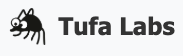

**Note**: this notebook is a more readable version of the notebook that scored our milestone-winning 1.21; unfortunately, we haven't had the same lucky result with this one. The original one is also shared here, but using it is not recommended: https://www.kaggle.com/code/jeroencottaar/taaf-duck-harness-kaggle

**Note**: if you make a copy of this notebook, you will have to manually select the proper GPU (RTX Pro 6000).

Link to writeup explaining what's going on here: https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3/discussion/717133

Link to Machine Learning Street Talk interview by Tim Scarfe about this duck harness: https://x.com/MLStreetTalk/status/2072326433922297975?s=20

This notebook executes the ARC-AGI-3 solver written by the Tufa Labs team; in alphabetical order: Harold Bessis, Jeroen Cottaar, Isaiah Pressman, Andries Smit, Michal Tesnar, and Stefano Viel.

You will only find infrastructure and diagnostics in this notebook; the actual solver code is in an attached dataset. See our writeup on the competition forum to learn more about that the solver actually does.

It installs the ARC runtime from the competition wheelhouse, makes the bundled source
snapshot importable, runs any solver setup commands, loads the pickled benchmark, plays the
competition games, and writes results to `/kaggle/working`. Diagnostics are minimised during
a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`) and kept full otherwise.

## 1. Environment and submission mode

Detect whether this is a real competition rerun (which minimises diagnostics), set the
framework's environment flags, and put the CUDA libraries on the linker path.

In [ ]:
import json
import os
import pickle
import subprocess
import sys
import sysconfig
import time
from datetime import datetime, timedelta
from pathlib import Path
from urllib.request import urlopen

# True only inside a real competition rerun; switches diagnostics + soft deadline.
TRUE_SUBMISSION = os.environ.get("KAGGLE_IS_COMPETITION_RERUN", "").strip().lower() in {"1", "true"}
NOTEBOOK_START_EPOCH = time.time()

# Non-interactive matplotlib backend: diagnostics render plots with no display attached.
os.environ["MPLBACKEND"] = "Agg"
# Marks the run as a (real or emulated) submission so the framework + solver can adjust.
os.environ["TAAF_RUN_AS_SUBMISSION"] = "1" if TRUE_SUBMISSION else "0"
# Skip periodic JSON/HTML diagnostics and per-frame logging for every run.
os.environ["TAAF_MINIMAL_DIAGNOSTICS"] = "1"

# Apply the measured vLLM winner before any serving setup command runs.
PUBLIC25_VLLM_PROFILE_NAME = 'kv12-bf16-mtp3-c12-cg48-reap448'
PUBLIC25_VLLM_PROFILE_ENV = {
    "TAAF_VLLM_ENABLE_PREFIX_CACHING": "0",
    "TAAF_VLLM_KV_CACHE_DTYPE": "auto",
    "TAAF_VLLM_KV_CACHE_MEMORY_BYTES": "12884901888",
    "TAAF_VLLM_MAX_CUDAGRAPH_CAPTURE_SIZE": "48",
    "TAAF_VLLM_MAX_NUM_BATCHED_TOKENS": "8192",
    "TAAF_VLLM_MAX_NUM_SEQS": "12",
    "TAAF_VLLM_MTP_TOKENS": "3",
    "TAAF_VLLM_OMP_THREADS": "1"
}
for key, value in PUBLIC25_VLLM_PROFILE_ENV.items():
    os.environ[key] = value
print(
    f'PUBLIC25_VLLM_PROFILE name={PUBLIC25_VLLM_PROFILE_NAME} '
    f'env={json.dumps(PUBLIC25_VLLM_PROFILE_ENV, sort_keys=True)}',
    flush=True,
)
# ARM P: load-time REAP-k448 pruning (vLLM general plugin), installed before serving setup starts vLLM.
_PRUNE_DIR = Path("/tmp/flashnext_prune_pkg")
(_PRUNE_DIR / "flashnext_prune").mkdir(parents=True, exist_ok=True)
(_PRUNE_DIR / "flashnext_prune-0.1.dist-info").mkdir(parents=True, exist_ok=True)
(_PRUNE_DIR / "flashnext_prune" / "__init__.py").write_text('"""Prune Qwen3.8-Flash-Next\'s routed experts at load time with a fixed per-layer keep mask (REAP-k448).\n\nA vLLM general plugin (entry point `vllm.general_plugins`), so it runs in every engine/worker process.\nTarget model only: MoE blocks built inside `Qwen3_8FlashNextModel.__init__` see `num_experts = len(keep)`;\neverything else (the PLE identity gate, the MTP draft, which builds from its own draft config) keeps seeing\nthe checkpoint\'s 512. `Qwen3_8FlashNextModel.load_weights` drops pruned experts, renumbers kept experts\n0..K-1 and slices router rows, then fuses the shared expert at index K.\n\nEnv: FLASHNEXT_PRUNE_MASK=/path/mask.json  ({"<layer>": [kept original expert ids, in new order]}).\nUnset -> the plugin does nothing.\n"""\nimport contextlib\nimport functools\nimport json\nimport os\nimport re\nimport sys\nimport threading\n\n_EXPERT = re.compile(r"(^|\\.)layers\\.(\\d+)\\.mlp\\.experts\\.(\\d+)\\.")\n_ROUTER = re.compile(r"(^|\\.)layers\\.(\\d+)\\.mlp\\.gate\\.weight$")\n_STATE = threading.local()\n\n\ndef _log(msg):\n    print(f"FLASHNEXT_PRUNE pid={os.getpid()} {msg}", file=sys.stderr, flush=True)\n\n\ndef load_mask(path):\n    raw = json.loads(open(path).read())\n    mask = {int(k): list(map(int, v)) for k, v in raw.items()}\n    sizes = {len(v) for v in mask.values()}\n    assert len(sizes) == 1, f"ragged mask {sizes}"\n    for layer, kept in mask.items():\n        assert len(set(kept)) == len(kept), f"duplicate expert in layer {layer}"\n    return mask, sizes.pop()\n\n\ndef filter_weights(weights, mask, stats):\n    """Yield (name, tensor) with pruned experts dropped, kept experts renumbered, routers row-sliced.\n    Names outside `mask` layers (e.g. MTP) pass through unchanged."""\n    remap = {layer: {old: new for new, old in enumerate(kept)} for layer, kept in mask.items()}\n    for name, tensor in weights:\n        if "mtp." in name:          # the MTP bank keeps all experts\n            yield name, tensor\n            continue\n        m = _EXPERT.search(name)\n        if m and int(m[2]) in remap:\n            layer, old = int(m[2]), int(m[3])\n            new = remap[layer].get(old)\n            if new is None:\n                stats["dropped"] += 1\n                continue\n            stats["renumbered"] += 1\n            yield name[:m.start(3)] + str(new) + name[m.end(3):], tensor\n            continue\n        r = _ROUTER.search(name)\n        if r and int(r[2]) in remap:\n            kept = mask[int(r[2])]\n            assert tensor.shape[0] > max(kept), (name, tuple(tensor.shape))\n            stats["routers"] += 1\n            yield name, _take_rows(tensor, kept)\n            continue\n        yield name, tensor\n\n\ndef _take_rows(tensor, rows):\n    try:\n        import torch\n        return tensor.index_select(0, torch.as_tensor(rows, dtype=torch.long, device=tensor.device)).contiguous()\n    except ImportError:          # offline tests with numpy arrays\n        return tensor[rows]\n\n\n@contextlib.contextmanager\ndef _num_experts(config, value):\n    saved = config.num_experts\n    config.num_experts = value\n    try:\n        yield\n    finally:\n        config.num_experts = saved\n\n\ndef register():\n    path = os.environ.get("FLASHNEXT_PRUNE_MASK", "").strip()\n    if not path:\n        return\n    try:\n        from vllm.models.qwen3_8_flash_next.nvidia import model as m\n    except Exception as exc:        # API-server-only processes without the model stack\n        _log(f"skip: {type(exc).__name__}: {exc}")\n        return\n    if getattr(m, "_flashnext_prune", False):\n        return\n    mask, keep = load_mask(path)\n    Model, Moe = m.Qwen3_8FlashNextModel, m.Qwen3_8FlashNextSparseMoeBlock\n    orig_model_init, orig_moe_init, orig_load = Model.__init__, Moe.__init__, Model.load_weights\n\n    def model_init(self, *args, **kwargs):\n        _STATE.target = True        # MoE blocks built during THIS init are target-model blocks\n        try:\n            return orig_model_init(self, *args, **kwargs)\n        finally:\n            _STATE.target = False\n\n    def moe_init(self, vllm_config, prefix=""):\n        cfg = vllm_config.model_config.hf_text_config\n        if getattr(_STATE, "target", False):\n            assert cfg.num_experts == 512, cfg.num_experts\n            with _num_experts(cfg, keep):\n                out = orig_moe_init(self, vllm_config, prefix=prefix)\n            _STATE.blocks = getattr(_STATE, "blocks", 0) + 1\n            return out\n        return orig_moe_init(self, vllm_config, prefix=prefix)\n\n    totals = {"dropped": 0, "renumbered": 0, "routers": 0, "calls": 0}\n\n    def load_weights(self, weights):\n        # AutoWeightsLoader groups the checkpoint stream by submodule, so this runs once per contiguous run of\n        # text-model tensors (routers sit in separate BF16 shards). Count across calls; check once at the top.\n        stats = {"dropped": 0, "renumbered": 0, "routers": 0}\n        with _num_experts(self.config, keep):     # maybe_fuse_shared_experts puts the shared expert at index keep\n            loaded = orig_load(self, filter_weights(weights, mask, stats))\n        for k, v in stats.items():\n            totals[k] += v\n        totals["calls"] += 1\n        return loaded\n\n    def check_totals():\n        layers = len(mask)\n        _log(f"load_weights totals {totals} blocks={getattr(_STATE, \'blocks\', 0)} keep={keep} layers={layers}")\n        per_expert = totals["renumbered"] // (keep * layers)\n        assert per_expert > 0 and totals["routers"] == layers, totals\n        assert totals["renumbered"] == per_expert * keep * layers, totals\n        assert totals["dropped"] == per_expert * (512 - keep) * layers, totals\n\n    tops = [getattr(m, n) for n in ("Qwen3_8FlashNextForConditionalGeneration", "Qwen3_8FlashNextForCausalLM") if hasattr(m, n)]\n\n    def wrap_top(cls):\n        orig = cls.load_weights\n\n        def top_load_weights(self, weights):\n            depth = getattr(_STATE, "top_depth", 0)\n            _STATE.top_depth = depth + 1\n            try:\n                loaded = orig(self, weights)\n            finally:\n                _STATE.top_depth = depth\n            if depth == 0:                      # outermost model only (CausalLM may nest inside ConditionalGeneration)\n                check_totals()\n            return loaded\n        cls.load_weights = functools.wraps(orig)(top_load_weights)\n\n    Model.__init__ = functools.wraps(orig_model_init)(model_init)\n    Moe.__init__ = functools.wraps(orig_moe_init)(moe_init)\n    Model.load_weights = functools.wraps(orig_load)(load_weights)\n    for cls in tops:\n        wrap_top(cls)\n    m._flashnext_prune = True\n    _log(f"registered keep={keep} layers={len(mask)} mask={path}")\n')
(_PRUNE_DIR / "flashnext_prune-0.1.dist-info" / "METADATA").write_text("Metadata-Version: 2.1\nName: flashnext-prune\nVersion: 0.1\n")
(_PRUNE_DIR / "flashnext_prune-0.1.dist-info" / "entry_points.txt").write_text('[vllm.general_plugins]\nflashnext_prune = flashnext_prune:register\n')
(_PRUNE_DIR / "k448_mask_layers.json").write_text('{"0": [0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 78, 79, 80, 81, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 116, 118, 119, 120, 121, 122, 123, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 136, 137, 138, 139, 140, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 153, 154, 155, 156, 157, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 171, 172, 173, 174, 175, 176, 178, 179, 180, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 219, 220, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 237, 238, 239, 240, 241, 242, 243, 246, 247, 248, 249, 251, 253, 254, 256, 258, 259, 260, 261, 262, 264, 265, 266, 267, 268, 269, 270, 272, 273, 274, 275, 277, 278, 280, 282, 283, 284, 285, 287, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 301, 302, 303, 304, 305, 306, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 337, 338, 339, 340, 341, 342, 344, 346, 347, 348, 349, 350, 351, 352, 353, 354, 356, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 376, 377, 378, 379, 380, 381, 383, 384, 385, 386, 387, 389, 390, 392, 393, 394, 395, 396, 398, 399, 400, 401, 403, 404, 406, 408, 410, 411, 412, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 470, 471, 473, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 488, 489, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 511], "1": [0, 1, 2, 3, 4, 5, 6, 8, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 76, 77, 78, 79, 80, 82, 83, 84, 85, 86, 89, 90, 91, 92, 93, 94, 95, 97, 99, 101, 102, 103, 104, 105, 106, 107, 108, 109, 111, 112, 113, 114, 115, 117, 118, 119, 120, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 141, 142, 143, 144, 145, 146, 147, 149, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 168, 169, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 189, 190, 192, 193, 194, 195, 196, 197, 199, 200, 201, 202, 203, 204, 206, 208, 209, 210, 211, 212, 213, 214, 215, 217, 218, 219, 220, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 237, 238, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 254, 255, 256, 257, 258, 259, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 273, 274, 275, 276, 278, 279, 281, 282, 283, 284, 285, 286, 287, 290, 291, 293, 294, 295, 296, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 312, 313, 314, 315, 316, 317, 319, 320, 321, 322, 324, 325, 326, 327, 328, 329, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 362, 363, 364, 365, 366, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 426, 427, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 453, 454, 455, 456, 458, 459, 460, 461, 462, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 479, 480, 481, 482, 483, 484, 486, 487, 488, 489, 490, 491, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 504, 505, 506, 507, 508, 510], "2": [0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 27, 28, 29, 30, 32, 33, 34, 35, 36, 37, 39, 40, 41, 42, 43, 44, 45, 46, 47, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 76, 77, 78, 79, 80, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 95, 96, 97, 100, 101, 102, 103, 104, 105, 106, 107, 108, 112, 113, 114, 117, 119, 120, 121, 122, 123, 124, 125, 127, 128, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 157, 158, 160, 161, 162, 163, 164, 165, 166, 168, 169, 170, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 217, 219, 220, 221, 222, 223, 224, 226, 228, 229, 230, 231, 232, 233, 234, 236, 237, 238, 239, 240, 241, 242, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 256, 257, 258, 259, 260, 263, 264, 265, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 279, 280, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 310, 311, 312, 313, 314, 315, 316, 317, 319, 320, 321, 322, 323, 324, 325, 326, 327, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 353, 354, 355, 356, 357, 358, 359, 360, 362, 363, 364, 365, 366, 367, 369, 370, 371, 372, 373, 374, 375, 377, 378, 379, 380, 382, 383, 384, 385, 387, 388, 390, 391, 392, 393, 394, 395, 396, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 421, 422, 423, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 508, 511], "3": [0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 23, 24, 26, 27, 28, 29, 30, 32, 33, 34, 35, 36, 38, 39, 40, 41, 43, 44, 45, 46, 47, 49, 50, 51, 52, 53, 54, 55, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 77, 78, 79, 80, 82, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 122, 123, 124, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 138, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 156, 158, 159, 160, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 178, 179, 181, 183, 185, 186, 187, 188, 189, 190, 191, 193, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 208, 209, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 235, 237, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 256, 257, 258, 259, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 282, 283, 284, 286, 287, 288, 289, 290, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 308, 309, 310, 311, 312, 313, 314, 315, 316, 321, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 359, 360, 362, 363, 364, 366, 367, 368, 369, 370, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 385, 386, 387, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 406, 408, 410, 411, 412, 413, 415, 416, 417, 418, 419, 420, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 461, 464, 465, 466, 467, 469, 470, 471, 474, 475, 476, 477, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "4": [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 90, 91, 92, 93, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 134, 135, 136, 137, 138, 139, 140, 141, 143, 145, 147, 148, 149, 150, 152, 153, 154, 155, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 171, 172, 174, 175, 176, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 221, 222, 223, 224, 225, 226, 228, 230, 231, 232, 233, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 263, 264, 265, 267, 268, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 292, 293, 294, 295, 296, 297, 298, 299, 300, 302, 303, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 318, 320, 321, 323, 324, 325, 326, 327, 328, 329, 330, 331, 333, 334, 336, 337, 338, 339, 340, 341, 342, 343, 345, 346, 347, 348, 349, 350, 351, 354, 357, 358, 359, 360, 361, 362, 363, 364, 366, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 384, 386, 387, 388, 389, 390, 392, 393, 394, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 412, 413, 414, 416, 417, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 445, 446, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 461, 462, 463, 464, 465, 467, 469, 470, 471, 472, 473, 474, 475, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 499, 501, 503, 504, 505, 506, 507, 508, 509, 510, 511], "5": [0, 1, 2, 3, 4, 5, 6, 7, 9, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 49, 51, 52, 54, 56, 57, 58, 59, 60, 61, 62, 63, 64, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 90, 91, 92, 93, 95, 96, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 109, 110, 111, 112, 113, 115, 117, 118, 119, 120, 121, 123, 124, 125, 126, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 158, 159, 160, 161, 163, 164, 165, 167, 169, 170, 171, 172, 173, 174, 175, 176, 178, 179, 180, 181, 182, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 202, 203, 204, 205, 206, 208, 209, 211, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 245, 246, 247, 249, 250, 251, 252, 253, 255, 257, 258, 259, 260, 261, 262, 264, 266, 267, 268, 269, 270, 273, 274, 275, 277, 278, 279, 280, 281, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 324, 325, 326, 328, 329, 330, 331, 333, 334, 335, 337, 338, 339, 340, 341, 342, 343, 345, 346, 347, 348, 349, 350, 351, 353, 354, 355, 357, 358, 359, 360, 361, 362, 363, 364, 365, 367, 368, 369, 370, 371, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 385, 386, 387, 388, 389, 390, 391, 392, 394, 395, 396, 397, 398, 399, 400, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 413, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 434, 435, 436, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 480, 481, 482, 483, 484, 485, 486, 487, 490, 491, 492, 493, 494, 495, 496, 497, 498, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "6": [1, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 39, 40, 42, 43, 45, 46, 47, 48, 49, 50, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 77, 79, 80, 81, 82, 84, 85, 86, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 100, 101, 102, 103, 104, 105, 106, 108, 109, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 131, 132, 134, 135, 136, 137, 138, 139, 140, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 156, 157, 158, 161, 162, 164, 166, 167, 168, 169, 170, 171, 172, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 201, 202, 205, 206, 207, 208, 209, 210, 211, 212, 214, 215, 216, 217, 219, 220, 221, 222, 223, 224, 225, 226, 227, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 267, 269, 270, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 308, 309, 310, 312, 314, 315, 316, 317, 318, 319, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 338, 339, 340, 341, 343, 344, 345, 347, 348, 349, 350, 351, 352, 353, 354, 355, 357, 358, 360, 361, 363, 364, 365, 366, 367, 368, 369, 371, 372, 374, 375, 376, 377, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 406, 407, 408, 409, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 427, 428, 429, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 444, 445, 446, 447, 448, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 489, 490, 491, 492, 493, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "7": [0, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 27, 28, 29, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 47, 48, 49, 51, 52, 53, 54, 55, 56, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 70, 71, 72, 73, 74, 75, 76, 78, 80, 81, 82, 83, 84, 85, 86, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 101, 102, 103, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 147, 148, 150, 152, 154, 155, 156, 157, 158, 159, 160, 161, 162, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 192, 193, 194, 195, 197, 198, 199, 200, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 239, 240, 241, 242, 244, 245, 246, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 267, 268, 269, 272, 273, 274, 275, 276, 277, 278, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 294, 295, 296, 297, 298, 299, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 314, 315, 317, 318, 319, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 338, 339, 340, 341, 342, 343, 344, 346, 347, 349, 350, 351, 352, 353, 354, 355, 357, 358, 359, 360, 361, 363, 365, 366, 367, 368, 369, 371, 372, 374, 375, 376, 377, 378, 379, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 401, 402, 403, 404, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 436, 437, 438, 439, 440, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 461, 462, 463, 464, 465, 466, 467, 469, 470, 471, 472, 473, 474, 475, 476, 477, 479, 480, 481, 482, 485, 486, 487, 488, 489, 490, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 511], "8": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 16, 17, 19, 20, 21, 23, 24, 26, 27, 28, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 85, 86, 87, 88, 89, 90, 91, 92, 93, 95, 96, 97, 98, 99, 100, 101, 103, 104, 105, 106, 107, 108, 109, 110, 111, 113, 115, 116, 117, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 169, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 193, 194, 195, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 227, 228, 229, 230, 232, 233, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 260, 261, 262, 264, 265, 266, 268, 269, 270, 271, 272, 273, 274, 275, 277, 278, 279, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 292, 294, 295, 296, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 312, 313, 314, 315, 316, 317, 318, 319, 320, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 343, 344, 345, 346, 347, 348, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 363, 365, 366, 367, 368, 369, 370, 371, 374, 375, 376, 377, 378, 379, 380, 381, 383, 384, 386, 387, 390, 392, 393, 394, 395, 396, 398, 399, 401, 402, 403, 404, 405, 406, 407, 410, 411, 412, 413, 415, 416, 417, 418, 419, 420, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 436, 437, 439, 440, 441, 442, 443, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 493, 494, 495, 496, 497, 498, 499, 500, 502, 503, 505, 506, 508, 509, 510, 511], "9": [0, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 23, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 66, 67, 68, 69, 70, 71, 72, 73, 74, 76, 77, 78, 79, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 93, 94, 95, 96, 97, 98, 99, 101, 102, 103, 104, 105, 107, 108, 109, 111, 112, 113, 114, 115, 116, 118, 119, 121, 122, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 139, 140, 141, 142, 143, 144, 145, 146, 147, 149, 150, 152, 153, 154, 155, 156, 157, 158, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 176, 177, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 198, 199, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 216, 218, 219, 220, 221, 222, 223, 224, 225, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 252, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 273, 274, 275, 276, 277, 278, 279, 280, 283, 284, 285, 286, 287, 288, 289, 291, 292, 293, 294, 295, 296, 297, 299, 300, 301, 302, 303, 304, 306, 307, 308, 309, 310, 313, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 344, 345, 346, 347, 348, 349, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 363, 364, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 407, 408, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 449, 450, 451, 452, 455, 456, 457, 458, 459, 460, 461, 463, 464, 466, 467, 468, 470, 471, 472, 473, 474, 475, 476, 477, 478, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 497, 498, 499, 500, 501, 502, 504, 505, 506, 507, 508, 511], "10": [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 34, 35, 37, 38, 39, 41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 59, 60, 61, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 74, 75, 77, 78, 79, 81, 82, 83, 84, 85, 87, 88, 89, 90, 91, 92, 93, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 125, 127, 128, 130, 131, 132, 133, 134, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 150, 151, 152, 153, 154, 155, 156, 157, 158, 160, 161, 162, 163, 164, 165, 166, 168, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 187, 188, 189, 191, 194, 195, 196, 197, 198, 199, 200, 201, 202, 205, 206, 207, 208, 209, 211, 212, 213, 214, 215, 216, 217, 218, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 256, 257, 258, 259, 260, 261, 262, 263, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 280, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 320, 321, 322, 323, 324, 325, 326, 327, 328, 330, 331, 332, 333, 334, 335, 336, 337, 338, 340, 341, 343, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 358, 361, 362, 363, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 377, 378, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 413, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 452, 454, 455, 458, 460, 461, 462, 463, 464, 465, 467, 468, 469, 470, 471, 472, 473, 474, 476, 477, 478, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510], "11": [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 20, 22, 24, 25, 26, 28, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 55, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 81, 82, 83, 84, 85, 86, 87, 88, 89, 91, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 187, 188, 189, 191, 192, 193, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 213, 214, 215, 217, 220, 221, 222, 223, 224, 225, 226, 229, 230, 231, 232, 233, 235, 237, 239, 240, 241, 242, 243, 244, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 262, 263, 265, 266, 268, 269, 270, 271, 272, 273, 274, 275, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 291, 292, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 311, 312, 313, 314, 316, 317, 318, 319, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 365, 368, 369, 370, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 432, 433, 434, 435, 436, 437, 439, 440, 442, 443, 444, 445, 447, 449, 450, 451, 452, 454, 455, 457, 459, 460, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 490, 491, 492, 493, 494, 496, 497, 498, 499, 500, 501, 502, 503, 505, 506, 507, 509, 510, 511], "12": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 32, 33, 34, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 57, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 102, 103, 106, 107, 108, 109, 110, 111, 112, 113, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 127, 129, 130, 131, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 183, 184, 185, 187, 188, 189, 190, 191, 192, 194, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 209, 210, 211, 213, 215, 216, 217, 218, 219, 220, 221, 223, 224, 225, 226, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 246, 247, 248, 249, 251, 252, 253, 254, 255, 256, 257, 258, 259, 261, 263, 265, 266, 267, 268, 269, 270, 272, 273, 274, 276, 277, 278, 279, 280, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 296, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 317, 318, 319, 320, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 342, 343, 345, 346, 347, 348, 349, 350, 351, 352, 353, 355, 356, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 382, 383, 384, 385, 386, 387, 389, 390, 391, 392, 393, 394, 395, 396, 398, 399, 400, 401, 403, 404, 405, 406, 408, 409, 410, 411, 412, 413, 414, 416, 417, 418, 419, 420, 422, 423, 424, 425, 426, 427, 428, 429, 430, 432, 433, 434, 435, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 478, 479, 480, 482, 483, 484, 485, 486, 487, 488, 489, 490, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "13": [0, 1, 2, 3, 4, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 67, 69, 70, 71, 72, 73, 74, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 118, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 144, 145, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 190, 191, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 205, 206, 207, 208, 209, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 237, 238, 239, 240, 241, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 257, 258, 260, 261, 263, 264, 265, 266, 268, 269, 270, 273, 274, 275, 276, 277, 278, 279, 280, 281, 283, 284, 286, 287, 288, 290, 291, 292, 293, 294, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 339, 341, 342, 344, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 384, 385, 387, 388, 389, 390, 391, 392, 394, 395, 396, 397, 398, 399, 401, 402, 403, 404, 405, 406, 407, 409, 410, 411, 412, 413, 414, 415, 416, 417, 419, 420, 421, 422, 423, 425, 426, 427, 428, 429, 431, 432, 435, 436, 437, 438, 439, 440, 441, 442, 443, 445, 446, 447, 448, 449, 450, 451, 452, 454, 455, 457, 459, 461, 462, 463, 465, 466, 467, 469, 471, 472, 473, 474, 475, 476, 477, 478, 479, 481, 482, 483, 484, 485, 486, 487, 489, 490, 491, 492, 493, 495, 496, 497, 498, 499, 500, 501, 503, 504, 505, 506, 507, 508, 510, 511], "14": [0, 1, 3, 5, 6, 8, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 82, 83, 84, 85, 86, 87, 89, 91, 92, 93, 94, 95, 96, 97, 98, 99, 101, 102, 103, 104, 105, 107, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 123, 124, 125, 126, 127, 128, 130, 131, 132, 133, 134, 136, 137, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 158, 159, 160, 161, 162, 164, 166, 167, 169, 170, 171, 172, 173, 174, 175, 177, 178, 179, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 253, 254, 256, 258, 259, 260, 262, 263, 264, 265, 266, 267, 268, 269, 270, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 314, 315, 316, 317, 318, 319, 320, 323, 324, 325, 326, 328, 329, 330, 331, 332, 333, 334, 336, 337, 340, 341, 342, 343, 344, 345, 347, 348, 349, 351, 352, 353, 354, 355, 356, 357, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 394, 395, 396, 397, 398, 401, 403, 404, 405, 406, 408, 409, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 432, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 476, 479, 480, 481, 483, 484, 485, 486, 487, 489, 491, 492, 493, 494, 496, 497, 498, 499, 500, 502, 503, 504, 505, 506, 507, 508, 509, 511], "15": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 28, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 92, 93, 94, 98, 99, 100, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 133, 134, 135, 136, 138, 139, 140, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 172, 173, 174, 175, 176, 177, 178, 180, 181, 182, 183, 184, 185, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 215, 216, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 235, 236, 237, 238, 239, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 252, 254, 255, 256, 259, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 274, 275, 277, 278, 279, 280, 281, 282, 283, 284, 286, 287, 288, 290, 291, 292, 293, 294, 295, 296, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 319, 320, 321, 322, 323, 324, 325, 326, 327, 329, 331, 333, 335, 336, 337, 338, 340, 341, 342, 343, 344, 346, 347, 348, 349, 350, 351, 352, 353, 354, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 370, 371, 372, 373, 374, 375, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 402, 403, 404, 406, 407, 408, 409, 410, 412, 414, 415, 416, 417, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 444, 445, 446, 447, 448, 449, 450, 451, 453, 454, 455, 456, 457, 458, 459, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 473, 475, 476, 477, 479, 480, 481, 482, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510], "16": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 27, 28, 29, 31, 33, 34, 35, 36, 39, 40, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 61, 62, 63, 64, 65, 66, 68, 69, 70, 71, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 118, 119, 120, 121, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 135, 136, 138, 139, 140, 142, 143, 144, 145, 146, 147, 148, 149, 151, 152, 153, 154, 155, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 212, 213, 214, 215, 216, 217, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 249, 250, 251, 252, 253, 255, 256, 258, 259, 260, 262, 263, 265, 266, 267, 268, 270, 271, 272, 273, 274, 275, 276, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 298, 299, 300, 303, 304, 306, 308, 309, 310, 311, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 328, 329, 330, 331, 332, 333, 334, 335, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 375, 376, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 389, 391, 392, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 417, 418, 419, 420, 421, 422, 424, 425, 426, 427, 428, 429, 430, 432, 433, 434, 435, 436, 438, 439, 440, 441, 442, 443, 444, 446, 447, 448, 449, 450, 451, 452, 453, 454, 456, 457, 459, 460, 462, 463, 465, 466, 467, 468, 469, 470, 471, 473, 474, 475, 476, 478, 479, 480, 481, 482, 483, 484, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 499, 500, 501, 502, 503, 504, 505, 507, 508, 511], "17": [0, 1, 3, 4, 5, 6, 7, 8, 10, 11, 12, 14, 15, 16, 17, 18, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 47, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 78, 79, 80, 81, 82, 83, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 127, 129, 130, 132, 133, 134, 135, 136, 137, 138, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 153, 154, 156, 159, 160, 161, 162, 163, 164, 165, 168, 169, 170, 171, 172, 173, 174, 175, 177, 180, 181, 182, 183, 184, 186, 187, 188, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 234, 235, 236, 237, 238, 239, 240, 242, 243, 244, 245, 246, 247, 248, 249, 251, 252, 253, 254, 255, 256, 257, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 309, 310, 311, 312, 313, 314, 315, 316, 317, 319, 320, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 332, 333, 334, 336, 337, 338, 339, 340, 343, 345, 346, 347, 348, 349, 350, 351, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 364, 365, 367, 368, 369, 370, 371, 372, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 389, 390, 391, 392, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 409, 410, 411, 413, 414, 415, 416, 418, 419, 420, 421, 422, 423, 425, 426, 427, 428, 429, 430, 431, 432, 433, 435, 436, 437, 439, 440, 441, 442, 443, 444, 446, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 475, 477, 478, 480, 482, 484, 485, 486, 487, 488, 489, 490, 491, 492, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "18": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 24, 26, 28, 29, 30, 31, 33, 34, 35, 36, 37, 38, 41, 42, 43, 44, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 79, 80, 81, 82, 83, 84, 85, 87, 88, 90, 91, 92, 93, 94, 95, 96, 97, 98, 100, 101, 103, 104, 105, 106, 107, 108, 109, 111, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 136, 137, 138, 139, 140, 141, 142, 143, 144, 146, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 159, 160, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 176, 178, 179, 180, 181, 182, 183, 184, 185, 188, 190, 192, 193, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 282, 283, 284, 285, 286, 287, 288, 289, 291, 292, 293, 294, 296, 297, 298, 299, 300, 302, 303, 304, 305, 306, 307, 308, 309, 310, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 343, 344, 346, 347, 348, 349, 351, 352, 353, 354, 355, 356, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 373, 374, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 390, 391, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 407, 408, 409, 411, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 427, 428, 429, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 453, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 475, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 490, 491, 493, 494, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 509, 510, 511], "19": [0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 31, 32, 33, 34, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 84, 86, 88, 89, 90, 91, 92, 93, 94, 95, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 138, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 152, 153, 154, 155, 156, 157, 158, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 172, 173, 174, 175, 176, 177, 179, 180, 181, 182, 183, 184, 185, 187, 189, 190, 191, 192, 193, 195, 196, 197, 198, 199, 200, 201, 202, 203, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 220, 222, 223, 225, 227, 228, 229, 230, 231, 232, 233, 234, 236, 237, 238, 240, 241, 242, 243, 244, 245, 246, 247, 249, 250, 251, 252, 253, 254, 255, 257, 258, 259, 260, 261, 262, 263, 264, 265, 267, 269, 270, 271, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 284, 285, 286, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 334, 335, 336, 337, 338, 339, 341, 342, 343, 344, 346, 347, 348, 349, 350, 352, 353, 354, 355, 356, 357, 358, 359, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 380, 381, 382, 383, 384, 385, 386, 387, 389, 390, 391, 392, 393, 395, 396, 398, 399, 400, 401, 402, 405, 406, 407, 408, 409, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 426, 427, 428, 429, 431, 432, 433, 434, 435, 437, 438, 439, 440, 442, 443, 444, 445, 446, 447, 448, 450, 452, 453, 454, 456, 457, 458, 460, 461, 462, 463, 464, 465, 467, 468, 469, 470, 471, 472, 473, 474, 477, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "20": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18, 19, 21, 23, 24, 25, 26, 27, 28, 29, 30, 31, 33, 34, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 68, 69, 70, 71, 73, 74, 75, 76, 78, 79, 80, 82, 83, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 102, 103, 104, 105, 106, 107, 108, 109, 112, 113, 114, 115, 116, 117, 118, 119, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 162, 164, 166, 167, 168, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 249, 251, 252, 253, 256, 257, 258, 259, 260, 261, 262, 263, 265, 266, 270, 272, 273, 274, 275, 277, 278, 280, 281, 283, 284, 285, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 300, 301, 303, 304, 305, 308, 309, 310, 311, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 373, 374, 376, 377, 378, 379, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 399, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 412, 413, 414, 416, 417, 418, 419, 420, 421, 423, 424, 425, 426, 427, 428, 430, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 448, 449, 450, 451, 452, 453, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 472, 473, 474, 475, 477, 478, 479, 480, 481, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "21": [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 61, 62, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 88, 89, 90, 91, 92, 93, 94, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 122, 123, 126, 129, 130, 131, 132, 134, 135, 136, 138, 139, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 178, 179, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 194, 195, 196, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 233, 234, 236, 237, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 255, 256, 257, 258, 259, 260, 261, 262, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 322, 323, 324, 325, 326, 327, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 344, 345, 347, 350, 351, 352, 354, 355, 356, 357, 358, 359, 360, 362, 363, 364, 366, 367, 369, 370, 371, 372, 373, 374, 376, 377, 378, 379, 380, 381, 383, 384, 385, 386, 387, 388, 389, 391, 392, 393, 394, 395, 396, 398, 399, 400, 401, 402, 403, 404, 405, 407, 409, 411, 412, 413, 414, 415, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 428, 429, 431, 432, 433, 434, 435, 436, 438, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 488, 489, 490, 491, 494, 495, 496, 497, 498, 499, 502, 503, 504, 505, 506, 507, 510, 511], "22": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 35, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 118, 120, 121, 122, 123, 124, 125, 126, 128, 130, 131, 132, 133, 134, 135, 136, 138, 139, 140, 141, 142, 143, 144, 145, 146, 148, 149, 150, 151, 152, 153, 154, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 169, 170, 171, 172, 173, 174, 175, 177, 178, 179, 180, 181, 182, 183, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 227, 229, 230, 231, 232, 233, 234, 235, 237, 238, 239, 240, 241, 242, 243, 244, 246, 247, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 261, 264, 265, 266, 267, 269, 270, 273, 274, 275, 276, 277, 279, 280, 281, 282, 283, 284, 285, 287, 288, 289, 290, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 316, 317, 318, 319, 320, 321, 322, 324, 325, 326, 327, 328, 329, 330, 332, 334, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 353, 354, 355, 356, 357, 358, 359, 361, 362, 363, 366, 367, 368, 369, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 389, 390, 392, 393, 394, 396, 397, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 413, 414, 415, 416, 417, 418, 419, 420, 423, 424, 425, 426, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 452, 453, 454, 455, 456, 457, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 477, 478, 479, 481, 482, 484, 485, 487, 489, 490, 491, 492, 493, 494, 495, 496, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 509, 510, 511], "23": [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15, 16, 18, 19, 20, 22, 24, 25, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 39, 41, 43, 44, 45, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 92, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 124, 125, 126, 127, 128, 129, 131, 132, 133, 134, 135, 137, 138, 139, 140, 141, 142, 144, 145, 146, 147, 149, 151, 152, 153, 154, 155, 156, 157, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 174, 175, 176, 179, 180, 181, 182, 183, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 196, 197, 198, 199, 200, 201, 202, 204, 205, 206, 207, 208, 209, 210, 211, 213, 214, 215, 217, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 242, 243, 244, 245, 246, 247, 248, 250, 251, 253, 254, 255, 256, 257, 259, 260, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 274, 275, 276, 277, 278, 279, 280, 281, 282, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 311, 312, 313, 314, 315, 316, 317, 318, 319, 322, 323, 325, 326, 327, 328, 329, 330, 331, 332, 334, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 351, 352, 353, 354, 356, 357, 358, 359, 360, 361, 362, 363, 365, 366, 367, 368, 370, 372, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 488, 489, 490, 492, 493, 494, 496, 497, 498, 499, 500, 501, 502, 503, 504, 506, 507, 508, 509, 510, 511], "24": [0, 1, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 17, 18, 19, 20, 21, 23, 24, 25, 26, 27, 28, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 85, 86, 87, 88, 89, 90, 91, 92, 93, 95, 96, 97, 98, 99, 100, 101, 103, 104, 105, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 119, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 133, 134, 135, 136, 138, 139, 140, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 154, 155, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 209, 210, 211, 213, 214, 215, 216, 217, 218, 219, 220, 221, 223, 224, 225, 227, 228, 229, 230, 232, 233, 234, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 268, 269, 270, 271, 272, 273, 275, 276, 277, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 290, 291, 292, 293, 294, 295, 296, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 353, 354, 355, 356, 357, 358, 360, 361, 363, 365, 366, 367, 368, 369, 370, 371, 372, 375, 376, 377, 378, 381, 383, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 401, 402, 403, 404, 405, 406, 407, 409, 410, 411, 412, 413, 416, 417, 418, 419, 420, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 436, 437, 439, 440, 441, 442, 443, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 477, 478, 479, 480, 482, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 508, 509, 510, 511], "25": [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 23, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 57, 58, 59, 60, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 87, 88, 89, 90, 91, 93, 94, 95, 96, 97, 98, 99, 100, 102, 103, 104, 105, 106, 107, 108, 109, 111, 112, 113, 114, 115, 116, 118, 119, 120, 121, 122, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 139, 140, 141, 142, 143, 144, 145, 146, 147, 149, 150, 152, 153, 154, 155, 156, 157, 158, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 176, 177, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 198, 199, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 216, 218, 219, 220, 221, 222, 223, 224, 225, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 249, 250, 252, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 272, 273, 274, 275, 276, 277, 278, 279, 280, 284, 285, 286, 287, 288, 289, 291, 292, 293, 295, 296, 299, 300, 301, 302, 303, 304, 307, 308, 309, 310, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 332, 333, 335, 336, 337, 338, 339, 340, 342, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 355, 356, 357, 358, 359, 360, 361, 363, 364, 366, 367, 368, 369, 370, 371, 372, 373, 374, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 393, 394, 395, 396, 397, 398, 399, 400, 401, 403, 404, 405, 407, 408, 409, 410, 411, 412, 413, 414, 416, 417, 418, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 445, 446, 447, 448, 449, 450, 451, 452, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 478, 480, 481, 482, 483, 484, 485, 487, 488, 489, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 508, 509, 511], "26": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 57, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 74, 77, 78, 79, 81, 82, 83, 84, 85, 87, 88, 89, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 117, 119, 120, 121, 122, 123, 124, 125, 126, 128, 129, 130, 131, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 145, 146, 147, 149, 151, 152, 153, 155, 156, 157, 158, 160, 161, 162, 163, 164, 165, 166, 167, 168, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 191, 194, 195, 196, 197, 198, 199, 200, 201, 202, 205, 206, 207, 208, 209, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 263, 264, 265, 266, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 282, 283, 284, 285, 286, 288, 289, 290, 291, 292, 293, 294, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 320, 321, 322, 323, 324, 325, 326, 327, 328, 330, 331, 332, 333, 334, 335, 336, 338, 339, 340, 341, 343, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 432, 433, 435, 436, 437, 438, 440, 441, 442, 443, 444, 445, 446, 447, 448, 450, 452, 453, 454, 455, 456, 457, 459, 460, 461, 464, 465, 467, 468, 469, 470, 472, 473, 474, 475, 476, 477, 478, 480, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 497, 499, 501, 502, 503, 504, 506, 507, 508, 509], "27": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 24, 25, 26, 27, 28, 31, 33, 34, 35, 36, 38, 39, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 85, 86, 87, 89, 91, 92, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 131, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 146, 147, 148, 149, 150, 152, 153, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 195, 196, 197, 199, 201, 202, 203, 204, 205, 206, 207, 209, 210, 211, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 260, 262, 263, 266, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 307, 308, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 363, 365, 368, 369, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 424, 425, 426, 427, 428, 429, 432, 433, 434, 437, 438, 439, 440, 442, 443, 444, 445, 446, 448, 449, 451, 452, 454, 455, 457, 458, 459, 460, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 505, 506, 507, 509, 510, 511], "28": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 60, 61, 62, 63, 64, 65, 67, 70, 71, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 106, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 118, 120, 121, 122, 123, 124, 125, 126, 127, 130, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 167, 168, 169, 170, 172, 173, 174, 175, 176, 177, 178, 179, 181, 184, 185, 186, 187, 188, 189, 190, 191, 193, 194, 195, 196, 197, 198, 200, 201, 202, 204, 205, 206, 207, 209, 211, 213, 214, 215, 216, 217, 218, 219, 220, 221, 223, 224, 225, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 257, 258, 259, 261, 262, 263, 264, 265, 266, 267, 268, 269, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 294, 295, 296, 297, 299, 300, 301, 302, 303, 305, 306, 307, 308, 311, 312, 313, 314, 315, 317, 318, 320, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 349, 350, 351, 352, 353, 355, 356, 357, 358, 359, 360, 361, 362, 363, 365, 366, 367, 369, 370, 371, 372, 373, 374, 375, 377, 378, 379, 380, 382, 383, 384, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 423, 424, 425, 426, 427, 429, 430, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 467, 468, 469, 470, 471, 472, 473, 475, 476, 478, 479, 480, 482, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "29": [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 21, 22, 23, 24, 25, 26, 27, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 144, 145, 147, 148, 149, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 163, 164, 166, 167, 168, 169, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 193, 194, 195, 196, 197, 198, 199, 201, 202, 203, 204, 205, 206, 207, 208, 209, 211, 212, 213, 214, 215, 216, 217, 218, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 237, 238, 239, 240, 241, 243, 244, 246, 247, 248, 249, 251, 252, 253, 254, 255, 257, 258, 259, 260, 261, 263, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 286, 287, 288, 290, 291, 292, 293, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 316, 318, 319, 320, 321, 322, 323, 324, 325, 326, 328, 329, 331, 332, 333, 334, 335, 336, 337, 339, 341, 342, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 401, 402, 403, 404, 405, 406, 407, 410, 412, 413, 414, 415, 416, 417, 419, 420, 421, 422, 423, 425, 426, 427, 428, 429, 430, 431, 432, 433, 435, 436, 437, 438, 439, 440, 441, 442, 443, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 459, 460, 461, 462, 463, 464, 465, 466, 467, 470, 471, 472, 473, 474, 475, 477, 478, 479, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 495, 496, 497, 499, 500, 501, 503, 504, 505, 506, 507, 508, 510, 511], "30": [0, 1, 3, 5, 6, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 101, 102, 103, 104, 105, 106, 107, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 123, 124, 125, 126, 127, 128, 130, 131, 132, 133, 134, 136, 137, 138, 139, 140, 141, 142, 143, 145, 146, 147, 149, 150, 151, 152, 153, 154, 155, 156, 158, 159, 160, 161, 162, 164, 166, 167, 169, 170, 171, 172, 173, 174, 175, 177, 178, 179, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 217, 218, 219, 221, 222, 223, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 247, 248, 249, 250, 251, 253, 254, 256, 258, 260, 261, 262, 263, 264, 267, 268, 269, 270, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 298, 299, 300, 301, 302, 303, 304, 305, 306, 308, 309, 310, 311, 313, 314, 315, 316, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 332, 333, 334, 336, 337, 340, 341, 342, 343, 344, 345, 347, 348, 349, 350, 351, 352, 354, 355, 356, 357, 359, 360, 361, 362, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 400, 401, 402, 403, 404, 405, 406, 408, 409, 411, 412, 413, 414, 415, 416, 417, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 446, 447, 448, 449, 450, 451, 453, 454, 455, 456, 458, 459, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 481, 483, 484, 485, 486, 487, 489, 491, 492, 493, 494, 496, 497, 498, 499, 500, 502, 503, 504, 505, 506, 507, 508, 509, 511], "31": [0, 1, 2, 3, 4, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 94, 96, 98, 99, 100, 101, 102, 105, 106, 108, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 155, 156, 157, 158, 159, 160, 161, 162, 163, 165, 166, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 181, 184, 185, 186, 187, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 201, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 226, 227, 228, 229, 231, 233, 234, 235, 236, 237, 238, 240, 241, 242, 244, 245, 246, 247, 248, 249, 250, 252, 253, 254, 255, 256, 258, 260, 261, 262, 263, 264, 265, 266, 267, 268, 271, 272, 273, 274, 275, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 315, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 332, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 346, 347, 348, 349, 350, 351, 352, 353, 355, 356, 357, 358, 360, 361, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 379, 380, 381, 382, 383, 384, 386, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 399, 400, 402, 403, 404, 405, 406, 408, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 436, 437, 438, 439, 440, 441, 442, 445, 446, 447, 449, 450, 451, 453, 454, 455, 456, 457, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 473, 474, 475, 476, 478, 479, 480, 481, 482, 484, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "32": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 27, 28, 29, 31, 32, 33, 34, 35, 39, 40, 42, 43, 44, 45, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 60, 61, 62, 63, 64, 65, 66, 70, 71, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 85, 87, 88, 89, 90, 91, 92, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 106, 108, 109, 110, 111, 112, 115, 116, 118, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 138, 139, 140, 142, 143, 144, 145, 146, 147, 148, 149, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 203, 204, 205, 207, 208, 209, 210, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 249, 250, 251, 252, 253, 254, 255, 256, 258, 259, 260, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 274, 275, 276, 277, 278, 279, 280, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 297, 298, 299, 300, 303, 304, 306, 308, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 365, 368, 369, 370, 372, 373, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 410, 411, 412, 413, 414, 415, 416, 417, 419, 420, 421, 422, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 436, 438, 439, 440, 441, 442, 443, 444, 446, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 473, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 499, 501, 502, 503, 504, 505, 506, 507, 508, 510, 511], "33": [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 17, 18, 19, 22, 23, 25, 26, 27, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 93, 94, 95, 96, 97, 98, 99, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 131, 132, 133, 134, 136, 137, 138, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 153, 154, 156, 158, 159, 160, 162, 163, 164, 165, 166, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 180, 181, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 201, 202, 204, 205, 206, 207, 208, 209, 210, 211, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 227, 228, 230, 231, 232, 234, 235, 236, 237, 238, 240, 241, 242, 243, 244, 245, 246, 247, 249, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 291, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 309, 310, 311, 312, 313, 314, 315, 316, 317, 319, 320, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 333, 334, 335, 336, 337, 338, 339, 340, 342, 343, 345, 346, 347, 348, 349, 350, 351, 354, 355, 356, 357, 358, 359, 360, 361, 362, 364, 365, 366, 367, 368, 369, 370, 371, 372, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 389, 390, 391, 392, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 409, 410, 411, 412, 413, 414, 415, 416, 418, 419, 420, 421, 422, 423, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 436, 437, 438, 440, 441, 442, 443, 444, 446, 448, 449, 450, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 474, 475, 476, 477, 479, 480, 481, 482, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 502, 503, 504, 505, 506, 508, 509, 510, 511], "34": [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29, 30, 33, 34, 36, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 57, 58, 59, 60, 62, 63, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 79, 80, 81, 82, 83, 84, 85, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 125, 126, 127, 128, 131, 132, 133, 134, 135, 137, 138, 139, 140, 141, 142, 143, 144, 146, 147, 148, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 187, 188, 189, 190, 192, 193, 195, 196, 197, 198, 199, 200, 203, 204, 206, 207, 208, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 248, 249, 251, 252, 253, 255, 256, 257, 258, 259, 260, 261, 264, 265, 266, 267, 268, 269, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 282, 283, 284, 285, 286, 287, 288, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 302, 303, 304, 305, 306, 307, 308, 310, 312, 314, 315, 316, 318, 319, 320, 321, 322, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 336, 337, 338, 340, 341, 343, 344, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 368, 369, 370, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 414, 415, 416, 417, 418, 419, 421, 422, 423, 424, 425, 426, 427, 428, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 477, 478, 480, 481, 482, 483, 484, 485, 486, 487, 488, 490, 492, 493, 494, 496, 497, 498, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "35": [0, 1, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 42, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 84, 86, 88, 89, 90, 91, 92, 93, 94, 96, 97, 99, 100, 101, 102, 103, 104, 105, 106, 107, 109, 110, 112, 113, 114, 115, 116, 117, 118, 119, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 165, 166, 167, 168, 169, 171, 172, 173, 174, 175, 176, 177, 178, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 220, 221, 222, 223, 225, 227, 228, 230, 231, 232, 233, 234, 236, 238, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 271, 273, 274, 275, 276, 277, 279, 280, 281, 282, 284, 285, 286, 287, 288, 289, 290, 291, 292, 294, 295, 296, 297, 298, 299, 300, 301, 302, 304, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 341, 342, 343, 344, 345, 347, 348, 349, 350, 353, 354, 356, 357, 358, 359, 360, 361, 362, 364, 365, 366, 367, 368, 369, 371, 372, 373, 374, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 395, 396, 397, 398, 399, 400, 401, 402, 403, 405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 417, 418, 419, 421, 423, 424, 426, 427, 428, 429, 431, 432, 433, 434, 435, 436, 437, 438, 440, 441, 442, 443, 444, 445, 446, 447, 448, 450, 452, 453, 454, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 471, 472, 473, 474, 475, 476, 477, 479, 480, 482, 483, 484, 485, 486, 487, 488, 489, 491, 492, 493, 494, 495, 496, 498, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "36": [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 33, 34, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 63, 64, 65, 66, 68, 69, 71, 72, 73, 74, 75, 76, 77, 78, 79, 81, 82, 83, 85, 86, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 112, 114, 115, 117, 118, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 151, 152, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 260, 262, 263, 264, 265, 266, 267, 271, 272, 274, 275, 276, 277, 278, 279, 283, 284, 285, 286, 287, 288, 289, 290, 291, 293, 294, 295, 296, 297, 298, 299, 300, 302, 303, 304, 305, 306, 308, 310, 311, 313, 314, 315, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 351, 352, 353, 354, 355, 356, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 372, 373, 374, 376, 377, 378, 379, 380, 381, 383, 384, 385, 386, 387, 388, 389, 390, 391, 393, 394, 395, 396, 397, 399, 401, 403, 404, 405, 406, 407, 408, 409, 411, 412, 413, 414, 415, 416, 417, 418, 421, 422, 423, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 444, 445, 446, 448, 449, 450, 451, 453, 454, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 471, 474, 475, 477, 478, 479, 480, 481, 483, 485, 486, 487, 488, 489, 490, 491, 493, 494, 495, 496, 497, 498, 499, 501, 502, 503, 504, 506, 507, 508, 509, 510, 511], "37": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 124, 129, 130, 131, 132, 134, 135, 136, 138, 139, 140, 141, 142, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 162, 163, 164, 165, 166, 167, 168, 169, 170, 172, 173, 174, 175, 176, 177, 178, 179, 181, 183, 184, 185, 186, 187, 188, 191, 192, 194, 195, 196, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 232, 233, 235, 236, 237, 239, 240, 242, 243, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 257, 259, 260, 261, 263, 264, 265, 266, 267, 268, 270, 271, 272, 275, 276, 277, 278, 279, 280, 281, 282, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 301, 302, 303, 304, 305, 306, 307, 308, 309, 311, 312, 313, 314, 316, 318, 320, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 342, 343, 344, 345, 347, 348, 349, 350, 351, 352, 354, 355, 356, 357, 358, 359, 360, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 376, 377, 378, 379, 380, 381, 383, 384, 385, 386, 387, 388, 389, 391, 392, 394, 395, 396, 398, 399, 400, 401, 402, 403, 404, 405, 407, 409, 411, 412, 413, 414, 415, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 488, 489, 492, 493, 494, 495, 496, 498, 499, 501, 502, 503, 504, 505, 506, 507, 508, 510, 511], "38": [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 39, 40, 41, 42, 43, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 56, 57, 59, 60, 62, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 74, 75, 76, 77, 78, 79, 81, 82, 83, 84, 85, 86, 87, 90, 91, 92, 93, 95, 96, 97, 99, 100, 101, 102, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 131, 132, 133, 134, 135, 136, 137, 138, 140, 141, 142, 143, 145, 146, 148, 149, 150, 151, 152, 153, 154, 157, 158, 159, 160, 162, 163, 164, 165, 166, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 209, 210, 212, 214, 215, 216, 218, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 332, 334, 335, 336, 337, 338, 339, 340, 341, 343, 344, 345, 346, 347, 348, 349, 350, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 368, 369, 371, 372, 373, 374, 375, 376, 377, 379, 380, 381, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 413, 414, 415, 416, 417, 418, 419, 420, 421, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 440, 441, 442, 443, 444, 445, 446, 447, 449, 450, 452, 453, 454, 456, 457, 458, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 477, 479, 481, 482, 483, 484, 485, 487, 489, 490, 491, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 509, 510, 511], "39": [0, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 16, 18, 19, 20, 21, 22, 24, 25, 26, 27, 30, 31, 32, 33, 34, 35, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 78, 79, 81, 82, 83, 84, 86, 87, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 107, 108, 109, 110, 111, 112, 114, 115, 117, 118, 119, 120, 121, 122, 123, 124, 125, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 139, 140, 141, 143, 144, 145, 146, 147, 148, 149, 151, 153, 154, 155, 156, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 198, 199, 200, 201, 202, 203, 205, 206, 207, 208, 209, 210, 212, 213, 214, 216, 217, 218, 219, 220, 222, 223, 224, 225, 226, 227, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 301, 303, 304, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 319, 320, 321, 322, 323, 324, 326, 327, 329, 330, 331, 333, 334, 335, 336, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 351, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 365, 366, 367, 368, 370, 371, 372, 373, 375, 376, 377, 378, 379, 380, 381, 382, 384, 385, 386, 387, 388, 389, 390, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 424, 425, 426, 427, 428, 429, 430, 431, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 449, 450, 451, 452, 453, 454, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 488, 489, 490, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 506, 507, 508, 509, 511], "40": [0, 3, 4, 6, 7, 8, 9, 12, 16, 17, 18, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 63, 64, 65, 66, 67, 68, 70, 71, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 103, 105, 106, 107, 108, 109, 110, 111, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 126, 127, 128, 130, 131, 132, 133, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 161, 162, 163, 165, 166, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 184, 186, 187, 188, 189, 190, 191, 192, 193, 195, 196, 197, 198, 199, 200, 203, 204, 205, 207, 208, 209, 210, 211, 212, 214, 215, 216, 217, 218, 219, 220, 222, 223, 224, 225, 226, 227, 228, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 242, 243, 244, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 274, 275, 276, 278, 279, 280, 281, 282, 283, 285, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 325, 326, 327, 329, 330, 331, 332, 333, 334, 335, 336, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 372, 373, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 406, 407, 408, 409, 410, 411, 416, 417, 418, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 439, 440, 441, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 455, 456, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 507, 508, 509, 510, 511], "41": [0, 1, 2, 3, 5, 8, 10, 12, 14, 15, 16, 17, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 55, 56, 58, 59, 61, 62, 64, 65, 66, 67, 68, 69, 71, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 102, 103, 104, 106, 107, 108, 109, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 122, 124, 125, 126, 127, 128, 129, 130, 132, 133, 134, 135, 136, 137, 138, 139, 140, 142, 143, 144, 145, 146, 147, 149, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 186, 187, 188, 189, 190, 192, 193, 194, 196, 198, 199, 200, 201, 202, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 228, 229, 230, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 250, 251, 252, 253, 254, 255, 256, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 272, 273, 274, 275, 276, 277, 278, 280, 281, 283, 284, 285, 286, 287, 288, 289, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 306, 307, 309, 310, 311, 312, 313, 314, 315, 316, 318, 319, 320, 321, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 340, 341, 342, 343, 344, 345, 347, 348, 350, 351, 352, 353, 354, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 367, 368, 369, 370, 371, 375, 376, 377, 378, 379, 380, 381, 382, 384, 385, 386, 387, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511], "42": [1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 64, 65, 67, 68, 69, 70, 71, 72, 73, 74, 75, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 99, 100, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 131, 132, 133, 134, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 151, 152, 153, 154, 156, 157, 158, 159, 160, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 182, 183, 184, 185, 186, 187, 188, 189, 190, 192, 194, 197, 198, 200, 202, 203, 204, 205, 206, 207, 208, 210, 211, 212, 213, 214, 215, 216, 217, 218, 220, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 241, 242, 243, 244, 245, 246, 248, 249, 250, 251, 252, 254, 255, 256, 257, 258, 259, 260, 261, 263, 264, 265, 266, 267, 268, 269, 270, 272, 273, 275, 276, 277, 278, 279, 280, 281, 283, 284, 285, 286, 287, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 307, 309, 310, 312, 313, 314, 315, 317, 319, 320, 322, 323, 325, 327, 328, 329, 330, 332, 333, 334, 335, 336, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 399, 401, 402, 403, 404, 408, 409, 410, 411, 412, 413, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 444, 445, 447, 448, 449, 450, 453, 454, 455, 456, 457, 458, 459, 462, 463, 464, 465, 466, 467, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 504, 506, 507, 508, 509, 510, 511], "43": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 112, 113, 114, 115, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 155, 156, 158, 160, 161, 162, 163, 164, 167, 169, 170, 171, 172, 173, 175, 176, 177, 178, 179, 180, 181, 182, 183, 185, 186, 187, 188, 189, 190, 192, 193, 194, 195, 198, 199, 201, 202, 203, 206, 207, 208, 209, 210, 211, 212, 213, 215, 217, 219, 220, 221, 223, 224, 226, 227, 228, 229, 230, 232, 233, 234, 235, 236, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 263, 264, 265, 266, 267, 268, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 284, 285, 286, 287, 288, 290, 291, 292, 293, 294, 295, 296, 297, 299, 300, 301, 302, 303, 304, 305, 306, 308, 310, 312, 313, 314, 315, 317, 318, 319, 320, 321, 322, 323, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 344, 345, 346, 347, 348, 349, 350, 351, 352, 354, 355, 356, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 391, 392, 393, 394, 395, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 410, 411, 412, 413, 414, 415, 416, 417, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 430, 431, 433, 434, 435, 436, 437, 438, 439, 441, 442, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 481, 482, 483, 484, 485, 486, 488, 489, 490, 491, 494, 495, 496, 497, 498, 499, 500, 501, 504, 505, 506, 507, 508, 509, 510, 511], "44": [0, 1, 2, 3, 4, 6, 11, 14, 15, 17, 18, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 39, 40, 41, 42, 43, 44, 45, 47, 48, 49, 50, 51, 54, 55, 56, 57, 58, 59, 62, 64, 65, 66, 67, 68, 69, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 126, 127, 128, 129, 131, 132, 133, 134, 135, 136, 137, 139, 140, 141, 142, 143, 144, 145, 147, 148, 149, 150, 151, 153, 155, 156, 157, 158, 160, 161, 162, 163, 164, 165, 167, 169, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 198, 199, 200, 201, 202, 203, 204, 206, 207, 208, 209, 210, 211, 212, 213, 214, 216, 217, 218, 220, 221, 222, 223, 224, 225, 226, 228, 229, 230, 231, 232, 233, 234, 235, 237, 238, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 296, 297, 298, 299, 300, 301, 302, 303, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 355, 356, 358, 359, 361, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 389, 390, 391, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 404, 405, 406, 407, 408, 409, 410, 411, 413, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 431, 432, 433, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 459, 460, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 498, 499, 500, 501, 502, 503, 505, 506, 507, 508, 509, 510, 511], "45": [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 18, 22, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 68, 69, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 82, 83, 84, 85, 87, 88, 89, 90, 93, 94, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 118, 119, 121, 122, 123, 124, 125, 126, 127, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 156, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 191, 193, 194, 195, 196, 198, 199, 200, 201, 202, 203, 204, 205, 207, 208, 209, 210, 211, 212, 213, 214, 215, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 244, 245, 247, 249, 250, 251, 252, 253, 254, 255, 256, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 269, 270, 271, 272, 274, 275, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 293, 294, 295, 296, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 318, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 332, 333, 334, 335, 336, 338, 339, 340, 341, 342, 343, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 357, 358, 359, 362, 363, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 378, 379, 381, 382, 383, 384, 385, 386, 387, 389, 390, 391, 392, 394, 395, 396, 397, 399, 400, 401, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 433, 434, 435, 437, 438, 439, 440, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 462, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 477, 478, 479, 480, 481, 482, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 500, 501, 502, 503, 504, 505, 506, 508, 509, 510, 511], "46": [1, 2, 3, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 20, 21, 22, 23, 24, 25, 28, 29, 30, 31, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 51, 52, 53, 54, 56, 57, 59, 60, 61, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 83, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 119, 120, 121, 122, 123, 124, 125, 126, 128, 129, 130, 131, 133, 135, 136, 137, 138, 139, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 154, 155, 156, 157, 158, 160, 161, 162, 163, 164, 165, 166, 167, 169, 170, 171, 172, 174, 175, 176, 177, 178, 179, 180, 181, 182, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 202, 204, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 236, 237, 238, 239, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 302, 303, 304, 305, 306, 308, 310, 311, 312, 314, 315, 316, 317, 318, 319, 320, 322, 323, 324, 325, 326, 327, 328, 329, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 376, 378, 379, 380, 381, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 397, 398, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 439, 441, 442, 443, 444, 445, 446, 448, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 477, 480, 481, 483, 484, 485, 486, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510], "47": [0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 20, 21, 23, 24, 26, 27, 28, 29, 30, 31, 33, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 59, 60, 61, 62, 64, 65, 66, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 82, 84, 85, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 102, 103, 105, 107, 108, 109, 110, 112, 113, 115, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 131, 132, 133, 134, 135, 136, 137, 138, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 156, 157, 159, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 190, 191, 192, 194, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 209, 210, 211, 212, 213, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 240, 241, 242, 243, 244, 245, 246, 247, 248, 250, 253, 254, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 288, 289, 290, 291, 292, 293, 295, 297, 298, 299, 300, 301, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 349, 350, 351, 352, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 368, 369, 370, 372, 374, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 438, 439, 440, 441, 442, 443, 444, 445, 446, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511]}')
os.environ["FLASHNEXT_PRUNE_MASK"] = str(_PRUNE_DIR / "k448_mask_layers.json")
os.environ["PYTHONPATH"] = os.pathsep.join([str(_PRUNE_DIR)] + ([os.environ["PYTHONPATH"]] if os.environ.get("PYTHONPATH") else []))
print("ARM P plugin installed", _PRUNE_DIR, flush=True)
# Pin arc_agi's cached level_reset_only before its client is built (RESET keeps the level).
os.environ["ONLY_RESET_LEVELS"] = "true"

# Prepend the CUDA toolkit to the linker path (it is off it on Kaggle GPU images) so the
# solver's GPU libraries (e.g. vllm / torch) can link against libcuda.
cuda_library_path = "/usr/local/nvidia/lib64"
os.environ["LIBRARY_PATH"] = os.pathsep.join(
    entry for entry in [cuda_library_path, *os.environ.get("LIBRARY_PATH", "").split(os.pathsep)] if entry
)

# Everything the run produces is written here.
WORKING_DIR = Path("/kaggle/working")
WORKING_DIR.mkdir(parents=True, exist_ok=True)
print(f"taaf.kaggle: TRUE_SUBMISSION={TRUE_SUBMISSION}")

## 2. Install the ARC runtime

Install `arc-agi` from the offline competition wheelhouse (the Kaggle submission environment
has no internet).

In [ ]:
# Install the ARC runtime from the bundled competition wheels.
# Quiet: stdout is discarded; stderr (and a non-zero exit) still surface real failures.
subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--no-index",
        "--no-warn-conflicts",
        "--disable-pip-version-check",
        "--find-links",
        "/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels",
        "arc-agi",
    ],
    stdout=subprocess.DEVNULL,
)

## 3. Locate the source bundle

Find the uploaded TAAF source dataset by its marker file, and record where Kaggle mounted
every attached input so setup commands and the solver can find them.

In [ ]:
# Kaggle inputs attached to this notebook, plus bookkeeping paths used below.
DATASET_SOURCES = ["pranavagrawai/duck-flash-next-kf-src", "keithtyser/qwen38-flash-next-vllm-nvfp4-runtime-v1"]
KERNEL_SOURCES = []
DATASET_BUNDLE_MARKER = "taaf-kaggle-bundle.json"
SETUP_ENV_PATH = WORKING_DIR / "taaf_setup_env.json"


# Locate the source dataset by its marker file rather than a fixed mount path.
def _find_bundle_dir() -> Path:
    for marker in Path("/kaggle/input").rglob(DATASET_BUNDLE_MARKER):
        return marker.parent
    raise RuntimeError("TAAF source bundle not found under /kaggle/input.")


# Kaggle mounts a dataset at /kaggle/input/<slug> or /kaggle/input/datasets/<owner>/<slug>
# (depending on owner / slug collisions), so probe both and use whichever exists. Utility
# scripts mount under /kaggle/usr/lib/notebooks/<owner>/<slug>.
def _dataset_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/input") / slug, Path("/kaggle/input/datasets") / owner / slug]


def _kernel_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/usr/lib/notebooks") / owner / slug]


def _first_existing(candidates: list[Path]) -> Path | None:
    return next((c for c in candidates if c.exists()), None)


BUNDLE_DIR = _find_bundle_dir()
print(f"taaf.kaggle: source bundle = {BUNDLE_DIR}")

# Map each attached input to where Kaggle actually mounted it (the source bundle is index 0).
kaggle_input_paths: dict[str, str] = {}
for i, ref in enumerate(DATASET_SOURCES):
    candidates = _dataset_mount_candidates(ref)
    resolved = BUNDLE_DIR if i == 0 else _first_existing(candidates)
    kaggle_input_paths[ref] = str(resolved or candidates[0])
for ref in KERNEL_SOURCES:
    candidates = _kernel_mount_candidates(ref)
    kaggle_input_paths[ref] = str(_first_existing(candidates) or candidates[0])

# Published to setup commands and the solver via the environment:
setup_env = {
    # JSON {ref: mount_path} so they can locate every attached dataset / utility script.
    "TAAF_KAGGLE_INPUT_PATHS": json.dumps(kaggle_input_paths, sort_keys=True),
    # The attached dataset refs in order (index 0 is this source bundle).
    "TAAF_KAGGLE_DATASET_SOURCES": json.dumps(DATASET_SOURCES),
    # The attached utility-script / kernel refs.
    "TAAF_KAGGLE_KERNEL_SOURCES": json.dumps(KERNEL_SOURCES),
}
os.environ.update(setup_env)
SETUP_ENV_PATH.write_text(json.dumps(setup_env, indent=2, sort_keys=True) + "\n")
print(f"taaf.kaggle: input paths = {setup_env['TAAF_KAGGLE_INPUT_PATHS']}")

## 4. Import the bundled source and run solver setup

Put the snapshotted repositories on the path (this process and any child processes), then run
the solver's setup commands â€” installing wheels, fetching model weights, and so on.

In [ ]:
# Each bundled repo exposes its importable tree at <repo>/src or <repo>.
def _source_path_entries(bundle_dir: Path) -> list:
    entries = []
    for repo in sorted((bundle_dir / "src").iterdir(), reverse=True):
        for candidate in (repo / "src", repo):
            if candidate.is_dir():
                entries.append(candidate)
    return entries


# Environment handed to each setup command (paths + any keys it has persisted).
def _command_env() -> dict:
    env = os.environ.copy()
    # "$PYTHON" in a command resolves to this notebook's interpreter.
    env["PYTHON"] = sys.executable
    # Absolute path to the mounted source bundle.
    env["TAAF_KAGGLE_BUNDLE_DIR"] = str(BUNDLE_DIR)
    # The writable /kaggle/working directory.
    env["TAAF_KAGGLE_WORKING_DIR"] = str(WORKING_DIR)
    # A command writes a JSON object here to persist env keys to later commands + the run.
    env["TAAF_KAGGLE_SETUP_ENV"] = str(SETUP_ENV_PATH)
    env.update({str(k): str(v) for k, v in json.loads(SETUP_ENV_PATH.read_text()).items()})
    return env


# Make the bundled repos importable here (sys.path) and in child processes (.pth).
source_entries = _source_path_entries(BUNDLE_DIR)
for entry in source_entries:
    sys.path.insert(0, str(entry))
pth_path = Path(sysconfig.get_paths()["purelib"]) / "taaf_kaggle_sources.pth"
pth_path.write_text("".join(f"{entry}\n" for entry in source_entries))
print(f"taaf.kaggle: wrote {pth_path} ({len(source_entries)} source roots)")

# Solver setup commands (wheels, vLLM server startup, ...) run before the benchmark loads.
env = _command_env()
for command in json.loads((BUNDLE_DIR / "setup_commands.json").read_text()):
    print(f"taaf.kaggle: setup command: {command}", flush=True)
    subprocess.run(command, shell=True, check=True, cwd=WORKING_DIR, env=env)
    # Re-read in case the command persisted new env keys.
    env = _command_env()
    os.environ.update(env)

# qwen38-fixes arm F on the Flash-Next stack: serving_setup.py pins a 60 s turn yield and is
# self-hash-checked, so override here, before the benchmark pickle imports tool_agent.
FIXES_ENV = {"LOCAL_ANALYZER_YIELD_SECONDS": "300", "DUCK_PROMPT_GAMEOVER_RETRY": "1", "DUCK_PROMPT_LEVELUP_REVIEW": "1"}
os.environ.update(FIXES_ENV)
SETUP_ENV_PATH.write_text(json.dumps({**json.loads(SETUP_ENV_PATH.read_text()), **FIXES_ENV}, indent=2, sort_keys=True) + "\n")
print(f"FIXES_ENV {json.dumps(FIXES_ENV, sort_keys=True)}", flush=True)

# Honour any PYTHONPATH a setup command exported.
for entry in reversed([e for e in os.environ.get("PYTHONPATH", "").split(os.pathsep) if e]):
    if entry not in sys.path:
        sys.path.insert(0, entry)

In [ ]:
# ARM P guard: pruning must be live in the served model before any game is played.
import re as _re
_log = (WORKING_DIR / "vllm-openai-server.log").read_text(errors="replace")
_lw = _re.findall(r"FLASHNEXT_PRUNE pid=\d+ load_weights totals (\{[^}]*\}) blocks=(\d+) keep=(\d+)", _log)
_mem = [float(x) for x in _re.findall(r"Model loading took ([\d.]+) GiB", _log)]
_kv = _re.findall(r"GPU KV cache size: ([\d,]+) tokens", _log)
print("ARM P GUARD", {"load_weights": _lw, "model_gib": _mem, "kv_tokens": _kv}, flush=True)
assert _lw and all(b == "48" and k == "448" for _, b, k in _lw), "pruning plugin did not run in the worker"
assert _mem and max(_mem) < 76.0, f"model memory {_mem} GiB: pruning did not free VRAM"
print("ARM P LIVE", flush=True)


## Speed screen

Serving benchmark on arm P: replay P1's 25 Duck sessions at sustained demand against stacked configs S0 (P), S1 (+MTP index sharing), S2 (+prefix caching, align), S3 (+MTP length). No games are played. See NEXT-PLAN.md.

In [ ]:
# SPEED SCREEN inputs: benchmark driver + P1's 25 parsed prompt snapshots.
import base64, gzip, hashlib
_BENCH = WORKING_DIR / 'bench'
_BENCH.mkdir(parents=True, exist_ok=True)
(_BENCH / 'speedbench.py').write_text('"""Serving benchmark: replay P\'s 25 Duck sessions against the local vLLM server at sustained demand.\n\nRuns inside the Kaggle notebook after the server is up (stdlib + requests only). Tested locally against\nbench/mock_server.py by bench/test_speedbench.py.\n\nWorkload model (mirrors Duck\'s tool_agent as far as serving is concerned):\n  - one session per game, all 25 at once (P: 25 games, 12 server slots, ~16 waiting);\n  - identical system prompt + python tool in every session (P\'s real prompt, parsed from its snapshots);\n  - a turn starts by trimming the oldest history block until the prompt is <= TURN_BUDGET tokens\n    (Duck\'s sliding window), then appends; within a turn requests are append-only (assistant + tool result);\n  - a turn ends when the model stops calling tools or after MAX_TURN_REQUESTS requests\n    (P1: 1,981 requests / ~1,057 turns = 1.9 per turn);\n  - Duck\'s sampling: temperature 0.6, top_p 0.95, top_k 20, thinking on, tool_choice auto, no max_tokens cap\n    beyond the context (P\'s max_tokens mean was 11.5K = context - prompt).\n"""\nfrom __future__ import annotations\n\nimport itertools\nimport json\nimport zlib\nimport re\nimport subprocess\nimport threading\nimport time\nfrom typing import Any\n\nimport requests\n\nBASE = "http://127.0.0.1:1234"\nMODEL = "Qwen/Qwen3.8-Flash-Next-NVFP4"\nCTX = 32_768\nTURN_BUDGET = 20_500\nMAX_TURN_REQUESTS = 2\nCHARS_PER_TOKEN = 3.37          # P: 71.8K chars of rendered input <-> 21.3K prompt tokens\nREQUEST_TIMEOUT = 900\nGREEDY_GAMES = 4\nGREEDY_BUDGET = 12_000\nGREEDY_MAX_TOKENS = 128\n\nCOUNTERS = (\n    "vllm:generation_tokens_total", "vllm:prompt_tokens_total", "vllm:num_preemptions_total",\n    "vllm:prefix_cache_queries_total", "vllm:prefix_cache_hits_total",\n    "vllm:spec_decode_num_drafts_total", "vllm:spec_decode_num_draft_tokens_total",\n    "vllm:spec_decode_num_accepted_tokens_total",\n)\nGAUGES = ("vllm:num_requests_running", "vllm:num_requests_waiting", "vllm:kv_cache_usage_perc")\nLINE = re.compile(r\'^([a-zA-Z_:][\\w:]*)(\\{[^}]*\\})?\\s+([-+0-9.eEinfINFnaN]+)$\')\n\n\ndef python_tool(description: str) -> list[dict[str, Any]]:\n    return [{"type": "function", "function": {\n        "name": "python", "description": description,\n        "parameters": {"type": "object", "properties": {"code": {\n            "type": "string",\n            "description": "Python code to run. The snippet is ephemeral and is not saved across tool calls."}},\n            "required": ["code"]}}}]\n\n\ndef payload(messages, tools, *, temperature=0.6, max_tokens=None, seed=None) -> dict[str, Any]:\n    p = {"model": MODEL, "messages": messages, "stream": False, "temperature": temperature, "top_p": 0.95,\n         "tools": tools, "tool_choice": "auto", "top_k": 20, "chat_template_kwargs": {"enable_thinking": True}}\n    if max_tokens is not None:\n        p["max_tokens"] = max_tokens\n    if seed is not None:\n        p["seed"] = seed\n    return p\n\n\ndef estimate_tokens(messages) -> int:\n    return int(sum(len(json.dumps(m, ensure_ascii=False)) for m in messages) / CHARS_PER_TOKEN)\n\n\ndef count_tokens(messages, tools, stats: dict) -> int:\n    try:\n        r = requests.post(f"{BASE}/tokenize", timeout=60, json={\n            "model": MODEL, "messages": messages, "tools": tools, "add_generation_prompt": True,\n            "chat_template_kwargs": {"enable_thinking": True}})\n        r.raise_for_status()\n        stats["tokenize_ok"] = stats.get("tokenize_ok", 0) + 1\n        return int(r.json()["count"])\n    except Exception:\n        stats["tokenize_fallback"] = stats.get("tokenize_fallback", 0) + 1\n        return estimate_tokens(messages)\n\n\ndef drop_oldest_block(hist: list[dict]) -> bool:\n    """Duck\'s _drop_oldest_history_block: remove from the front up to the next user message."""\n    nxt = next((i for i in range(1, len(hist)) if hist[i]["role"] == "user"), None)\n    if nxt is None:\n        return False\n    del hist[:nxt]\n    return True\n\n\ndef assistant_message(msg: dict) -> tuple[dict, list[dict]]:\n    out = {"role": "assistant", "content": msg.get("content") or ""}\n    reasoning = msg.get("reasoning_content") or msg.get("reasoning")\n    if reasoning:\n        out["reasoning_content"] = reasoning\n    calls = [{"id": c.get("id") or f"call-{i}", "type": "function",\n              "function": {"name": c["function"]["name"], "arguments": c["function"].get("arguments") or "{}"}}\n             for i, c in enumerate(msg.get("tool_calls") or [])]\n    if calls:\n        out["tool_calls"] = calls\n    return out, calls\n\n\nclass Session(threading.Thread):\n    def __init__(self, game: str, data: dict, tools, stop: threading.Event, records: list, lock: threading.Lock,\n                 stats: dict, start_delay: float):\n        super().__init__(daemon=True, name=f"session-{game}")\n        self.game, self.tools, self.stop, self.records, self.lock, self.stats = game, tools, stop, records, lock, stats\n        self.system = data["messages"][0]\n        self.hist = [dict(m) for m in data["messages"][1:]]\n        self.users = itertools.cycle(data["user_pool"])\n        self.tool_results = itertools.cycle(data["tool_pool"])\n        self.start_delay = start_delay\n\n    def run(self) -> None:\n        if self.stop.wait(self.start_delay):\n            return\n        n, in_turn, turn_start, prompt_est = 0, 0, True, 0\n        while not self.stop.is_set():\n            if turn_start:\n                while True:\n                    prompt_est = count_tokens([self.system, *self.hist], self.tools, self.stats)\n                    if prompt_est <= TURN_BUDGET or not drop_oldest_block(self.hist):\n                        break\n            messages = [self.system, *self.hist]\n            max_tokens = max(256, CTX - prompt_est - 512)\n            rec = {"game": self.game, "n": n, "turn_start": turn_start, "prompt_est": prompt_est,\n                   "t0": time.time()}\n            try:\n                r = requests.post(f"{BASE}/v1/chat/completions", timeout=REQUEST_TIMEOUT,\n                                  json=payload(messages, self.tools, max_tokens=max_tokens,\n                                               seed=zlib.crc32(f"{self.game}:{n}".encode()) & 0x7FFFFFFF))\n                rec["t1"], rec["status"] = time.time(), r.status_code\n                if r.status_code != 200:\n                    rec["error"] = r.text[:300]\n                    if r.status_code == 400 and ("context" in r.text.lower() or "input_tokens" in r.text):\n                        drop_oldest_block(self.hist)            # Duck\'s _force_reduce_messages\n                        turn_start = True\n                    with self.lock:\n                        self.records.append(rec)\n                    if self.stop.wait(1.0):\n                        return\n                    continue\n                body = r.json()\n            except Exception as exc:                            # server restarts end the config: not an error then\n                rec["t1"], rec["status"], rec["error"] = time.time(), -1, f"{type(exc).__name__}: {exc}"[:300]\n                with self.lock:\n                    self.records.append(rec)\n                if self.stop.wait(2.0):\n                    return\n                continue\n            choice = body["choices"][0]\n            usage = body.get("usage") or {}\n            msg, calls = assistant_message(choice["message"])\n            rec.update(prompt_tokens=usage.get("prompt_tokens"), completion_tokens=usage.get("completion_tokens"),\n                       finish=choice.get("finish_reason"), tool_calls=len(calls))\n            with self.lock:\n                self.records.append(rec)\n            self.hist.append(msg)\n            for c in calls:\n                self.hist.append({"role": "tool", "tool_call_id": c["id"], "content": next(self.tool_results)})\n            n += 1\n            in_turn += 1\n            if not calls or in_turn >= MAX_TURN_REQUESTS:\n                self.hist.append({"role": "user", "content": next(self.users)})\n                in_turn, turn_start = 0, True\n            else:\n                turn_start = False\n                prompt_est = (usage.get("prompt_tokens") or prompt_est) + (usage.get("completion_tokens") or 0) \\\n                    + estimate_tokens(self.hist[-len(calls):])\n\n\ndef parse_metrics(text: str) -> dict[str, float]:\n    out: dict[str, float] = {}\n    for line in text.splitlines():\n        m = LINE.match(line.strip())\n        if not m:\n            continue\n        name, labels, value = m[1], m[2] or "", float(m[3])\n        if name in COUNTERS or name in GAUGES:\n            out[name] = out.get(name, 0.0) + value\n        elif name == "vllm:spec_decode_num_accepted_tokens_per_pos_total":\n            pos = re.search(r\'position="(\\d+)"\', labels)\n            key = f"accepted_pos{pos[1] if pos else \'?\'}"\n            out[key] = out.get(key, 0.0) + value\n        elif name == "vllm:request_success_total":\n            out["request_success_total"] = out.get("request_success_total", 0.0) + value\n    return out\n\n\nclass Poller(threading.Thread):\n    def __init__(self, stop: threading.Event, interval: float = 5.0):\n        super().__init__(daemon=True, name="metrics-poller")\n        self.stop, self.interval, self.samples = stop, interval, []\n\n    def run(self) -> None:\n        while not self.stop.is_set():\n            self.samples.append(sample())\n            self.stop.wait(self.interval)\n\n\ndef gpu_memory_mib() -> float | None:\n    try:\n        out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],\n                             capture_output=True, text=True, timeout=20).stdout\n        return float(out.split()[0])\n    except Exception:\n        return None\n\n\ndef sample() -> dict:\n    s = {"t": time.time(), "gpu_mib": gpu_memory_mib()}\n    try:\n        s.update(parse_metrics(requests.get(f"{BASE}/metrics", timeout=20).text))\n    except Exception as exc:\n        s["metrics_error"] = f"{type(exc).__name__}: {exc}"[:200]\n    return s\n\n\ndef window(samples: list[dict], records: list[dict], t0: float, t1: float) -> dict:\n    inside = [s for s in samples if t0 <= s["t"] <= t1 and "vllm:generation_tokens_total" in s]\n    if len(inside) < 2:\n        return {"t0": t0, "t1": t1, "error": "too few metric samples"}\n    a, b = inside[0], inside[-1]\n    dt = b["t"] - a["t"]\n    d = {k: b[k] - a.get(k, 0.0) for k in b if k not in {"t", "gpu_mib", "metrics_error", *GAUGES}}\n    drafts = d.get("vllm:spec_decode_num_drafts_total", 0.0)\n    done = [r for r in records if r.get("status") == 200 and t0 <= r["t1"] <= t1]\n    lat = sorted(r["t1"] - r["t0"] for r in done)\n    mean = lambda xs: sum(xs) / len(xs) if xs else None\n    return {\n        "t0": a["t"], "t1": b["t"], "seconds": dt,\n        "gen_tok_s": d.get("vllm:generation_tokens_total", 0.0) / dt,\n        "prompt_tok_s": d.get("vllm:prompt_tokens_total", 0.0) / dt,\n        "requests_s": d.get("request_success_total", 0.0) / dt,\n        "client_completed": len(done),\n        "client_errors": sum(1 for r in records if r.get("status") != 200 and t0 <= r["t1"] <= t1),\n        "latency_mean_s": mean(lat), "latency_p50_s": lat[len(lat) // 2] if lat else None,\n        "prompt_tokens_mean": mean([r["prompt_tokens"] for r in done if r.get("prompt_tokens")]),\n        "completion_tokens_mean": mean([r["completion_tokens"] for r in done if r.get("completion_tokens")]),\n        "preemptions": d.get("vllm:num_preemptions_total", 0.0),\n        "prefix_hit_rate": (d.get("vllm:prefix_cache_hits_total", 0.0) / d["vllm:prefix_cache_queries_total"]\n                            if d.get("vllm:prefix_cache_queries_total") else None),\n        "accept_rate_by_pos": {k: v / drafts for k, v in sorted(d.items()) if k.startswith("accepted_pos")} if drafts else {},\n        "tokens_per_draft": (1 + d.get("vllm:spec_decode_num_accepted_tokens_total", 0.0) / drafts) if drafts else None,\n        "running_mean": mean([s.get("vllm:num_requests_running", 0.0) for s in inside]),\n        "waiting_mean": mean([s.get("vllm:num_requests_waiting", 0.0) for s in inside]),\n        "kv_usage_mean": mean([s.get("vllm:kv_cache_usage_perc", 0.0) for s in inside]),\n        "gpu_mib_max": max((s["gpu_mib"] for s in inside if s.get("gpu_mib") is not None), default=None),\n    }\n\n\ndef greedy_check(sessions: dict, tools) -> list[dict]:\n    """Deterministic outputs for a fixed set of prompts, each sent twice (the second can hit the prefix cache)."""\n    out = []\n    for game in sorted(sessions)[:GREEDY_GAMES]:\n        system, hist = sessions[game]["messages"][0], [dict(m) for m in sessions[game]["messages"][1:]]\n        stats: dict = {}\n        while count_tokens([system, *hist], tools, stats) > GREEDY_BUDGET and drop_oldest_block(hist):\n            pass\n        for attempt in (0, 1):\n            t0 = time.time()\n            try:\n                r = requests.post(f"{BASE}/v1/chat/completions", timeout=REQUEST_TIMEOUT, json=payload(\n                    [system, *hist], tools, temperature=0.0, max_tokens=GREEDY_MAX_TOKENS, seed=0))\n                m = r.json()["choices"][0]["message"] if r.status_code == 200 else {}\n                text = (m.get("reasoning_content") or m.get("reasoning") or "") + "␞" + (m.get("content") or "") \\\n                    + "␞" + json.dumps([c.get("function") or {} for c in m.get("tool_calls") or []], sort_keys=True)\n                out.append({"game": game, "attempt": attempt, "status": r.status_code, "text": text,\n                            "seconds": time.time() - t0, "prompt_tokens": (r.json().get("usage") or {}).get("prompt_tokens")\n                            if r.status_code == 200 else None, "error": None if r.status_code == 200 else r.text[:300]})\n            except Exception as exc:\n                out.append({"game": game, "attempt": attempt, "status": -1, "text": None,\n                            "seconds": time.time() - t0, "error": f"{type(exc).__name__}: {exc}"[:300]})\n    return out\n\n\ndef run_load(sessions: dict, tools, *, warmup_s: float, measure_s: float, windows: int,\n             poll_s: float = 5.0, stagger_s: float = 20.0) -> dict:\n    stop, lock, records, stats = threading.Event(), threading.Lock(), [], {}\n    poller = Poller(stop, poll_s)\n    poller.start()\n    threads = [Session(g, sessions[g], tools, stop, records, lock, stats, i * stagger_s / len(sessions))\n               for i, g in enumerate(sorted(sessions))]\n    started = time.time()\n    for t in threads:\n        t.start()\n    time.sleep(warmup_s + measure_s)\n    ended = time.time()\n    time.sleep(poll_s + 1)                     # one sample past the end so the last window closes on data\n    stop.set()\n    for t in threads:\n        t.join(timeout=5)\n    poller.join(timeout=poll_s + 30)\n    m0 = started + warmup_s\n    step = measure_s / windows\n    wins = [window(poller.samples, records, m0 + i * step, m0 + (i + 1) * step) for i in range(windows)]\n    total = window(poller.samples, records, m0, ended)\n    with lock:\n        recs = list(records)\n    turn_starts = sum(1 for r in recs if r.get("turn_start") and r.get("status") == 200)\n    ok = sum(1 for r in recs if r.get("status") == 200)\n    return {"started": started, "measure_start": m0, "ended": ended, "windows": wins, "total": total,\n            "requests_per_turn": ok / turn_starts if turn_starts else None, "stats": stats,\n            "records": recs, "samples": poller.samples,\n            "errors_after_warmup": sum(1 for r in recs if r.get("status") != 200 and r["t1"] >= m0 and r["t1"] <= ended)}\n')
_blob = gzip.decompress(base64.b64decode('...'))
assert hashlib.sha256(_blob).hexdigest() == '0ae68596552942e77ac3aec5250e86a599d7a23a7d15284f680cb0240edf166e'
(_BENCH / 'sessions.json').write_bytes(_blob)
print('SPEED_SCREEN inputs written', len(_blob), flush=True)


In [ ]:
# SPEED SCREEN: stacked serving configs on P, one server restart per config. Runs after the ARM P guard cell.
# Inputs defined by earlier notebook cells: WORKING_DIR, BUNDLE_DIR, PUBLIC25_VLLM_PROFILE_ENV, _command_env.
import importlib.util
import json
import os
import re
import shutil
import sys
import time
import traceback

BENCH_DIR = WORKING_DIR / "bench"
sys.path.insert(0, str(BENCH_DIR))
import speedbench as sb  # noqa: E402  (written by the previous cell)

WARMUP_S, MEASURE_S, WINDOWS = 180.0, 600.0, 5
DATA = json.loads((BENCH_DIR / "sessions.json").read_text())
SESSIONS, TOOLS = DATA["sessions"], sb.python_tool(DATA["tool_description"])
TUNING_KEYS = ("TAAF_VLLM_MTP_INDEX_SHARE_FOR_ITERATION", "TAAF_VLLM_ENABLE_PREFIX_CACHING", "TAAF_VLLM_MTP_TOKENS",
               "TAAF_VLLM_MAX_CUDAGRAPH_CAPTURE_SIZE")

os.environ.update(_command_env())                         # TAAF_KAGGLE_* for the serving setup module
_spec = importlib.util.spec_from_file_location("taaf_vllm_serving_setup", BUNDLE_DIR / "serving_setup.py")
setup = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(setup)
MODEL_DIR = setup.resolve_model_dir()


def log_evidence(text: str) -> dict:
    args = re.findall(r"non-default args: (\{.*)", text)
    return {
        "non_default_args": args[-1][:4000] if args else None,
        "prune_load_weights": re.findall(r"FLASHNEXT_PRUNE pid=\d+ load_weights totals (\{[^}]*\}) blocks=(\d+) keep=(\d+)", text),
        "model_gib": [float(x) for x in re.findall(r"Model loading took ([\d.]+) GiB", text)],
        "kv_tokens": re.findall(r"GPU KV cache size: ([\d,]+) tokens", text),
        "max_concurrency": re.findall(r"Maximum concurrency for [\d,]+ tokens per request: ([\d.]+)x", text),
        "mamba_cache_mode": re.findall(r"[Mm]amba cache mode is set to '(\w+)'", text)
                            + re.findall(r"Prefix caching in Mamba cache '(\w+)'", text),
        "index_share_in_args": bool(re.search(r"index_share_for_mtp_iteration['\"]?\s*:\s*[Tt]rue", text)),
        "prefix_caching_in_args": bool(re.search(r"enable_prefix_caching['\"]?\s*:\s*[Tt]rue", text)),
        "num_speculative_tokens": re.findall(r"num_speculative_tokens['\"]?\s*:\s*(\d+)", text)[-1:],
        "block_size": re.findall(r"[Ss]etting attention block size to (\d+)", text)[-1:],
        "error_lines": [l[:300] for l in text.splitlines() if re.search(r"Traceback|\bERROR\b|NotImplementedError", l)][:20],
    }


def set_profile(overrides: dict) -> None:
    for key in TUNING_KEYS:
        if key in PUBLIC25_VLLM_PROFILE_ENV:
            os.environ[key] = PUBLIC25_VLLM_PROFILE_ENV[key]
        else:
            os.environ.pop(key, None)
    os.environ.update(overrides)


def restart_server(overrides: dict) -> dict:
    set_profile(overrides)
    tuning = setup.resolve_vllm_tuning()
    env, _check = setup.runtime_environment(deep_preload_validation=False, tuning=tuning)
    identity = setup.start_server(MODEL_DIR, env, tuning=tuning)        # stops the owned server first
    readiness = setup.wait_for_server(identity, time.monotonic() + setup.SERVER_READY_TIMEOUT + 60)
    return {"tuning": tuning, "ready_seconds": readiness["ready_seconds"], "pid": identity.get("pid")}


def run_config(name: str, overrides: dict, *, restart: bool) -> dict:
    ev = {"name": name, "overrides": overrides, "started": time.time(), "ok": False}
    print(f"SPEED_SCREEN {name} start overrides={overrides}", flush=True)
    try:
        if restart:
            ev["restart"] = restart_server(overrides)
        ev["ready_wall_s"] = time.time() - ev["started"]
        log = setup.SERVER_LOG.read_text(errors="replace")
        ev["log"] = log_evidence(log)
        lw, mem = ev["log"]["prune_load_weights"], ev["log"]["model_gib"]
        assert lw and all(b == "48" and k == "448" for _, b, k in lw), "pruning plugin did not run in the worker"
        assert mem and max(mem) < 76.0, f"model memory {mem} GiB: pruning did not free VRAM"
        ev["greedy"] = sb.greedy_check(SESSIONS, TOOLS)
        load = sb.run_load(SESSIONS, TOOLS, warmup_s=WARMUP_S, measure_s=MEASURE_S, windows=WINDOWS)
        (BENCH_DIR / f"raw-{name}.json").write_text(json.dumps({"records": load.pop("records"),
                                                                "samples": load.pop("samples")}))
        ev["load"] = load
        ev["ok"] = True
        t = load["total"]
        print(f"SPEED_SCREEN {name} done " + json.dumps({key: t.get(key) for key in (
            "gen_tok_s", "requests_s", "running_mean", "kv_usage_mean", "prefix_hit_rate", "accept_rate_by_pos",
            "prompt_tokens_mean", "gpu_mib_max", "error")} | {"errors": load["errors_after_warmup"],
                                                             "req_per_turn": load["requests_per_turn"]},
            default=str), flush=True)
    except BaseException as exc:                               # record and move on to the next config
        ev["error"] = f"{type(exc).__name__}: {exc}"[:4000]
        ev["traceback"] = traceback.format_exc()[-6000:]
        print(f"SPEED_SCREEN {name} FAILED {ev['error'][:800]}", flush=True)
    finally:
        if setup.SERVER_LOG.exists():
            shutil.copy(setup.SERVER_LOG, BENCH_DIR / f"server-{name}.log")
        ev["ended"] = time.time()
        RESULTS["configs"][name] = ev
        (WORKING_DIR / "speed-screen.json").write_text(json.dumps(RESULTS, indent=1, default=str))
    return ev


def greedy_mismatches(a: list, b: list, attempt_a: int, attempt_b: int) -> int | None:
    ta = {r["game"]: r["text"] for r in a if r["attempt"] == attempt_a}
    tb = {r["game"]: r["text"] for r in b if r["attempt"] == attempt_b}
    if not ta or ta.keys() != tb.keys() or any(v is None for v in (*ta.values(), *tb.values())):
        return None
    return sum(ta[g] != tb[g] for g in ta)


RESULTS = {"plan": "analysis/kv-lever-scope-20260930/NEXT-PLAN.md", "warmup_s": WARMUP_S, "measure_s": MEASURE_S,
           "windows": WINDOWS, "turn_budget": sb.TURN_BUDGET, "max_turn_requests": sb.MAX_TURN_REQUESTS,
           "profile_P": PUBLIC25_VLLM_PROFILE_ENV, "configs": {}, "decisions": {}}

S1 = {"TAAF_VLLM_MTP_INDEX_SHARE_FOR_ITERATION": "1"}
S2 = {**S1, "TAAF_VLLM_ENABLE_PREFIX_CACHING": "1"}
run_config("S0", {}, restart=False)
run_config("S1", S1, restart=True)
run_config("S2", S2, restart=True)

# S3 = stack base + MTP length. Base is S2 if it ran and its prefix-cached greedy outputs agree with S1 no worse
# than S0 agrees with S1 (the numeric-noise floor); else S1 if it ran; else S0.
c = RESULTS["configs"]
noise = greedy_mismatches(c["S0"].get("greedy", []), c["S1"].get("greedy", []), 0, 0) if c["S1"]["ok"] and c["S0"]["ok"] else None
s2_cached = greedy_mismatches(c["S1"].get("greedy", []), c["S2"].get("greedy", []), 0, 1) if c["S1"]["ok"] and c["S2"]["ok"] else None
s2_equal = s2_cached is not None and s2_cached <= max(1, noise or 0)
base_name = "S2" if (c["S2"]["ok"] and s2_equal) else ("S1" if c["S1"]["ok"] else "S0")
base = {"S0": {}, "S1": S1, "S2": S2}[base_name]
acc = (c[base_name].get("load") or {}).get("total", {}).get("accept_rate_by_pos", {})
p2 = acc.get("accepted_pos2")
k = 2 if (p2 is not None and p2 < 0.35) else 4
S3 = {**base, "TAAF_VLLM_MTP_TOKENS": str(k)}
if k == 4:
    S3["TAAF_VLLM_MAX_CUDAGRAPH_CAPTURE_SIZE"] = "60"                 # 12 seqs x (1 + 4) tokens
RESULTS["decisions"] = {"greedy_noise_S0_vs_S1": noise, "greedy_S2cached_vs_S1": s2_cached, "s2_equal": s2_equal,
                        "s3_base": base_name, "base_pos2_acceptance": p2, "s3_mtp_tokens": k}
print("SPEED_SCREEN decisions", json.dumps(RESULTS["decisions"]), flush=True)
run_config("S3", S3, restart=True)

try:
    RESULTS["teardown"] = setup.stop_owned_server()
except BaseException as exc:
    RESULTS["teardown"] = {"error": f"{type(exc).__name__}: {exc}"}
(WORKING_DIR / "speed-screen.json").write_text(json.dumps(RESULTS, indent=1, default=str))
print("SPEED_SCREEN complete", {n: (e["ok"], e.get("error", "")[:120]) for n, e in RESULTS["configs"].items()}, flush=True)
